(motorcycle_regression)=
# Regression with input-dependent noise

This example fits a feed-forward network to head acceleration measured on a crash-test dummy in a
simulated motorcycle accident. The noise in the readings changes with time, so a network that predicts
only the mean misstates its uncertainty. A second network predicts a mean and a variance at every time
and fits both by maximum likelihood {cite:p}`nix1994estimating`. The readings are the motorcycle data of
{cite:t}`silverman1985spline`.

In [1]:
import pytensor

floatX = "float32"
pytensor.config.floatX = floatX

In [2]:
import urllib.request

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pytensor.tensor as pt

from tqdm.auto import tqdm

from pytensor_ml.activations import SoftPlus, Tanh
from pytensor_ml.layers import Input, Linear, Sequential
from pytensor_ml.loss import SquaredError
from pytensor_ml.model import Model
from pytensor_ml.optim import adam

## Data

The data are 133 readings of head acceleration, in g, at times from 2.4 to 57.6 milliseconds after
impact. Both are standardized before training and mapped back to physical units for the figures.

In [3]:
DATA_URL = (
    "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/MASS/mcycle.csv"
)
data_path = Path("../data/mcycle.csv")

if not data_path.exists():
    data_path.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, data_path)

times, acceleration = np.loadtxt(data_path, delimiter=",", skiprows=1, usecols=(1, 2), unpack=True)

time_mean, time_std = times.mean(), times.std()
acceleration_mean, acceleration_std = acceleration.mean(), acceleration.std()

X = ((times - time_mean) / time_std)[:, None].astype(floatX)
y = ((acceleration - acceleration_mean) / acceleration_std)[:, None].astype(floatX)
X.shape

(133, 1)

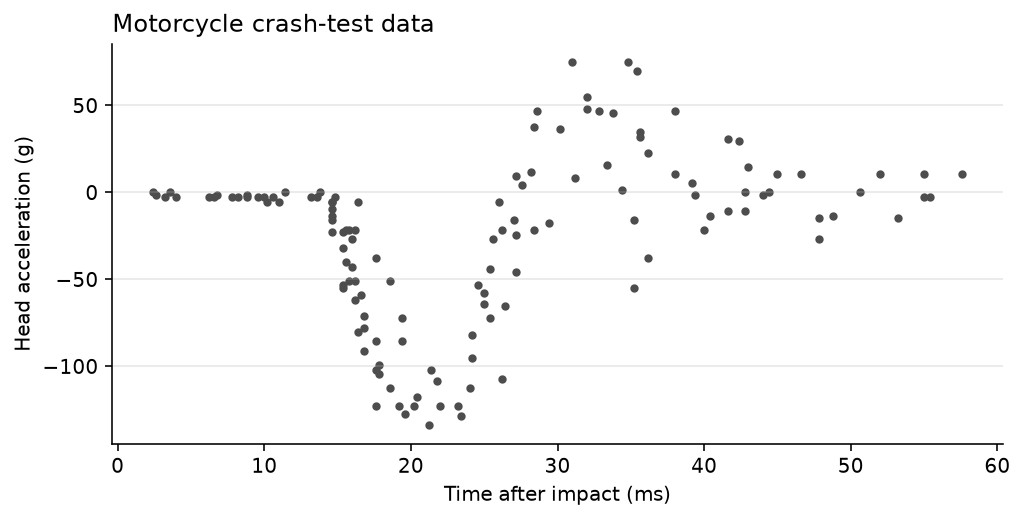

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=144, layout="constrained")
ax.scatter(times, acceleration, s=10, color="0.3")
ax.set(xlabel="Time after impact (ms)", ylabel="Head acceleration (g)")
ax.set_title("Motorcycle crash-test data", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

## Mean-only network

A network with two hidden layers of 16 tanh units maps standardized time to standardized acceleration.
Training it on {class}`~pytensor_ml.loss.SquaredError` is maximum likelihood under Gaussian noise with a
single variance shared by every reading, and the estimate of that variance is the mean squared residual.
The band it implies therefore has the same width at every time. With only 133 readings, every step uses
the full dataset. A wider network or a longer run starts fitting individual readings, which shrinks the
residuals and with them the estimated noise.

In [5]:
X_in = Input("X_in", shape=(None, 1))

mean_network = Sequential(
    Linear("mean_hidden_1", n_in=1, n_out=16),
    Tanh(),
    Linear("mean_hidden_2", n_in=16, n_out=16),
    Tanh(),
    Linear("mean_output", n_in=16, n_out=1),
)
mean_model = Model(mean_network(X_in)).initialize(seed=0)
mean_step = mean_model.compile_train(adam(learning_rate=3e-3), SquaredError())

In [6]:
n_steps = 2_000
mean_loss = [mean_step(X, y) for _ in tqdm(range(n_steps))]

  0%|          | 0/2000 [00:00<?, ?it/s]

In [7]:
time_grid = np.linspace(times.min(), times.max(), 400)
X_grid = ((time_grid - time_mean) / time_std)[:, None].astype(floatX)

residual_std = np.sqrt(np.mean((mean_model.predict(X) - y) ** 2))
mean_curve = mean_model.predict(X_grid)[:, 0] * acceleration_std + acceleration_mean
mean_band = 2 * residual_std * acceleration_std

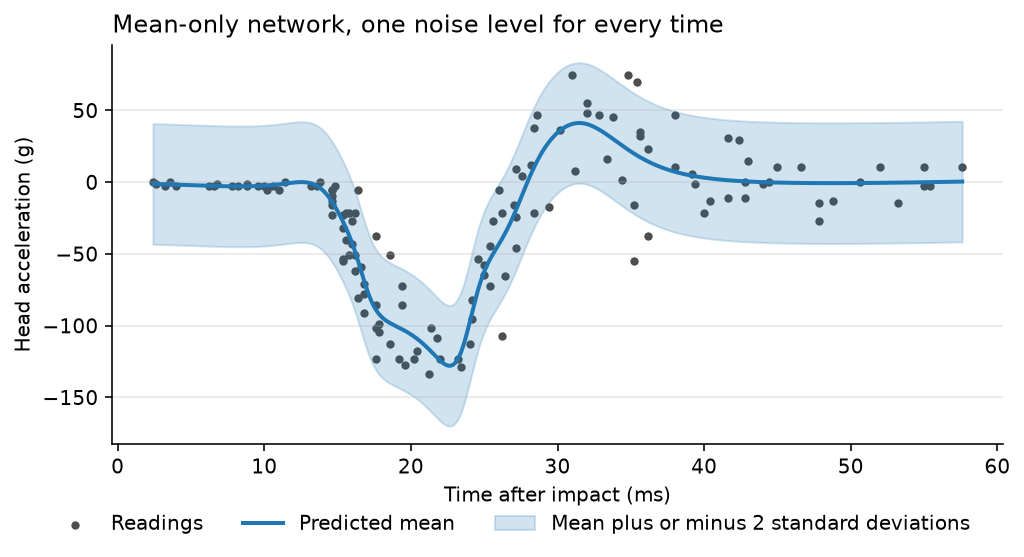

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=144, layout="constrained")
ax.scatter(times, acceleration, s=10, color="0.3", label="Readings")
ax.plot(time_grid, mean_curve, color="C0", linewidth=2, label="Predicted mean")
ax.fill_between(
    time_grid,
    mean_curve - mean_band,
    mean_curve + mean_band,
    color="C0",
    alpha=0.2,
    label="Mean plus or minus 2 standard deviations",
)
ax.set(xlabel="Time after impact (ms)", ylabel="Head acceleration (g)")
ax.set_title("Mean-only network, one noise level for every time", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(labels),
    frameon=False,
)
plt.show()

## Mean-variance network

The second network has the same hidden layers and two outputs. The first is the mean, and the second
passes through a {class}`~pytensor_ml.activations.SoftPlus` to become a variance, which keeps it
positive. Training minimizes the Gaussian negative log-likelihood of the readings,

$$
\frac{1}{2N} \sum_{i=1}^{N} \left( \log \sigma^2(t_i) + \frac{(y_i - \mu(t_i))^2}{\sigma^2(t_i)} \right),
$$

so a reading the mean misses by a lot can be explained by a larger variance at its time, at the cost of
the log-variance term. The library has no loss of this form, so the graph is written directly and passed
to {meth}`~pytensor_ml.model.Model.compile_train` as `loss`, along with the inputs the step reads.

In [9]:
variance_network = Sequential(
    Linear("variance_hidden_1", n_in=1, n_out=16),
    Tanh(),
    Linear("variance_hidden_2", n_in=16, n_out=16),
    Tanh(),
    Linear("variance_output", n_in=16, n_out=2),
)
outputs = variance_network(X_in)
predicted_mean = outputs[:, :1]
predicted_variance = SoftPlus()(outputs[:, 1:]) + 1e-6

y_target = Input("y_target", shape=(None, 1))
negative_log_likelihood = 0.5 * pt.mean(
    pt.log(predicted_variance) + (y_target - predicted_mean) ** 2 / predicted_variance
)

variance_model = Model(outputs).initialize(seed=0)
variance_step = variance_model.compile_train(
    adam(learning_rate=3e-3),
    loss=negative_log_likelihood,
    inputs=[X_in, y_target],
)

In [10]:
variance_loss = [variance_step(X, y) for _ in tqdm(range(n_steps))]

  0%|          | 0/2000 [00:00<?, ?it/s]

In [11]:
predict_distribution = pytensor.function(
    inputs=[X_in],
    outputs=[predicted_mean[:, 0], pt.sqrt(predicted_variance[:, 0])],
)
variance_mean, variance_std = predict_distribution(X_grid)

variance_curve = variance_mean * acceleration_std + acceleration_mean
variance_band = 2 * variance_std * acceleration_std

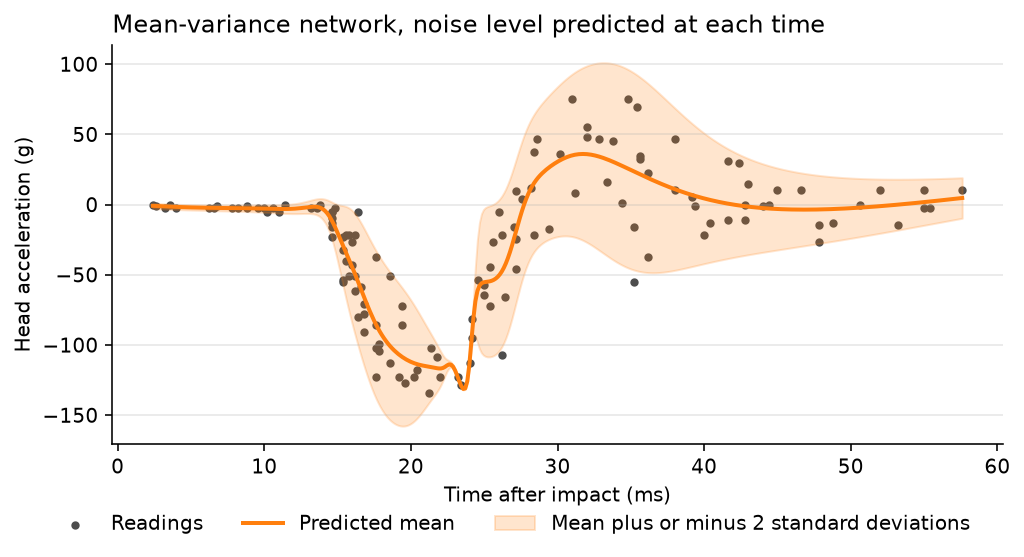

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=144, layout="constrained")
ax.scatter(times, acceleration, s=10, color="0.3", label="Readings")
ax.plot(time_grid, variance_curve, color="C1", linewidth=2, label="Predicted mean")
ax.fill_between(
    time_grid,
    variance_curve - variance_band,
    variance_curve + variance_band,
    color="C1",
    alpha=0.2,
    label="Mean plus or minus 2 standard deviations",
)
ax.set(xlabel="Time after impact (ms)", ylabel="Head acceleration (g)")
ax.set_title("Mean-variance network, noise level predicted at each time", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=len(labels),
    frameon=False,
)
plt.show()

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 8, 2026

## Watermark

In [13]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sun, 08 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

matplotlib : 3.11.2
numpy      : 2.5.4
pytensor   : 3.3.8
pytensor_ml: 0.4.0
tqdm       : 4.70.1

Watermark: 2.6.0



# Thumbnail Image

The cell below draws this notebook's card image for the docs gallery. Its `gallery-thumbnail` tag selects
it as the thumbnail, and its `remove-cell` tag, shared with this heading, keeps both off the rendered page.

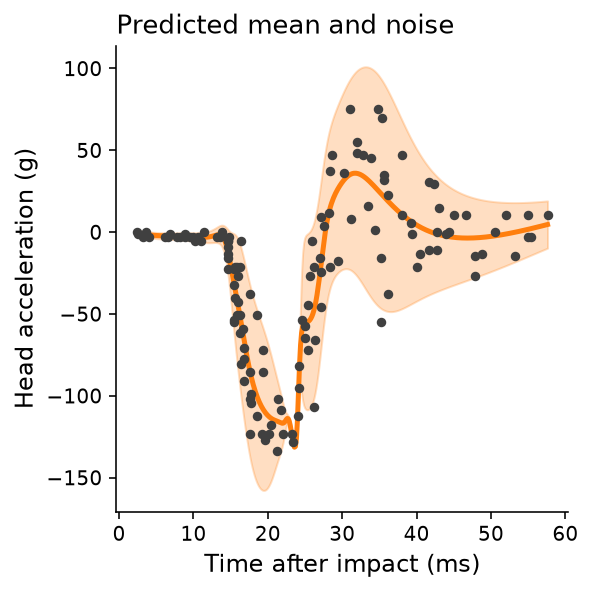

In [14]:
fig, ax = plt.subplots(figsize=(4, 4), dpi=144, layout="constrained")
ax.fill_between(
    time_grid,
    variance_curve - variance_band,
    variance_curve + variance_band,
    color="C1",
    alpha=0.25,
)
ax.plot(time_grid, variance_curve, color="C1", linewidth=2.5)
ax.scatter(times, acceleration, s=14, color="0.25", zorder=3)
ax.set_title("Predicted mean and noise", loc="left", fontsize=13)
ax.set_xlabel("Time after impact (ms)", fontsize=12)
ax.set_ylabel("Head acceleration (g)", fontsize=12)
ax.tick_params(labelsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.show()